# Phân loại Ảnh E3 Fashion-MNIST: LSTM so với GRU

Quy trình huấn luyện và đánh giá thử nghiệm trên tập dữ liệu E3 Fashion-MNIST sử dụng mạng hồi quy (recurrent-image-classification). Sổ tay này tái sử dụng các mô-đun của dự án, tự động ưu tiên sử dụng GPU nếu có, yêu cầu bộ nhớ đệm (cache) Fashion-MNIST đã tồn tại trong Google Drive, và ghi các tệp kết quả thực nghiệm lại vào Drive. Sổ tay này sẽ không tải xuống bộ dữ liệu mới.

## 1. Thiết lập môi trường và cấu hình các đường dẫn

In [ ]:
from pathlib import Path
import inspect
import json
import os
import subprocess
import sys
import time

# Tất cả các đường dẫn dự án, dữ liệu nguồn và thư mục đầu ra có thể thay đổi tại đây.
REPOSITORY_URL = "https://github.com/hoctran19-cyber/deep-learning-computer-vision-co5085.git"
BRANCH = "ex_3"
REPO_DIR = Path("/content/deep-learning-computer-vision-co5085")
DRIVE_MOUNT = Path("/content/drive")
DRIVE_ROOT = DRIVE_MOUNT / "MyDrive/ComputerVision/Exercise"
# Cấu hình ghi đè trực tiếp
FASHION_MNIST_DATA_DIR = DRIVE_ROOT / "data"
E1_DATA_SEARCH_ROOTS = [
    DRIVE_ROOT / "deep-learning-computer-vision-co5085/E1/data",
    DRIVE_ROOT / "E1/data",
]
OUTPUT_DIR = DRIVE_ROOT / "E3_experiments/fashion_mnist_lstm_gru"
INSTALL_DEPENDENCIES = True
SEED = 42
VALIDATION_SPLIT = 0.10
BATCH_SIZE = 128
EPOCHS = 10
LEARNING_RATE = 1e-3
NUM_WORKERS = 2

IN_COLAB = Path("/content").exists() and "google.colab" in sys.modules
if not IN_COLAB:
    raise RuntimeError("Sổ tay này được thiết kế cho Google Colab. Hãy mở nó trong Colab và chạy từ đầu đến cuối.")
print(f"Python: {sys.version.split()[0]} | Colab: {IN_COLAB}")

Python: 3.13.16 | Colab: True


## 2. Kết nối Google Drive

In [ ]:
from google.colab import drive
drive.mount(str(DRIVE_MOUNT), force_remount=False)
if not DRIVE_ROOT.is_dir():
    raise FileNotFoundError(f"Google Drive MyDrive was not found at {DRIVE_ROOT}")
print(f"Drive mounted: {DRIVE_ROOT}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted: /content/drive/MyDrive/ComputerVision/Exercise


## 3. Sao chép (Clone) hoặc cập nhật nhánh `ex_3` và cài đặt các thư viện phụ thuộc

In [ ]:
if REPO_DIR.exists():
    if not (REPO_DIR / ".git").is_dir():
        raise RuntimeError(f"{REPO_DIR} đã tồn tại nhưng không phải là một kho lưu trữ Git; hãy thay đổi REPO_DIR trong ô thiết lập.")
    subprocess.run(["git", "-C", str(REPO_DIR), "fetch", "origin", BRANCH], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "checkout", "-B", BRANCH, f"origin/{BRANCH}"], check=True)
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only", "origin", BRANCH], check=True)
else:
    subprocess.run(["git", "clone", "--branch", BRANCH, "--single-branch", REPOSITORY_URL, str(REPO_DIR)], check=True)
os.chdir(REPO_DIR)
print(f"Kho lưu trữ đã sẵn sàng: {REPO_DIR} (nhánh {BRANCH})")

if INSTALL_DEPENDENCIES:
    requirements = REPO_DIR / "requirements.txt"
    if not requirements.is_file():
        raise FileNotFoundError(f"Không tìm thấy tệp danh sách thư viện phụ thuộc: {requirements}")

    # Đọc yêu cầu cài đặt và loại bỏ dòng torch/torchvision có định dạng phiên bản cứng nhắc để tránh xung đột với Python 3.13 trong Colab
    req_content = requirements.read_text()
    modified_reqs = []
    for line in req_content.splitlines():
        if "torch" in line.lower() or "torchvision" in line.lower():
            # Giữ lại tên thư viện nhưng bỏ khai báo phiên bản khắt khe (ví dụ chuyển thành torch)
            clean_line = line.split("==")[0].split(">=")[0].strip()
            modified_reqs.append(clean_line)
        else:
            modified_reqs.append(line)

    temp_requirements = Path("/content/temp_requirements.txt")
    temp_requirements.write_text("\n".join(modified_reqs))

    # Thực hiện cài đặt các thư viện từ tệp cấu hình đã được điều chỉnh thích ứng
    subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(temp_requirements)], check=True)

# Nhập (Import) gói E3 từ thư mục gốc của dự án vừa tải về.
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
print("Các thư viện phụ thuộc đã sẵn sàng.")

Kho lưu trữ đã sẵn sàng: /content/deep-learning-computer-vision-co5085 (nhánh ex_3)
Các thư viện phụ thuộc đã sẵn sàng.


## 4. Tìm và xác minh bộ dữ liệu E1 Fashion-MNIST hiện có

Chỉ chấp nhận bộ nhớ đệm (cache) Fashion-MNIST của torchvision đã được xử lý trước đó. Nếu không tìm thấy, quá trình thực thi sẽ dừng lại; không cho phép tự động tải xuống hoặc sử dụng dữ liệu thay thế. Hãy điều chỉnh `FASHION_MNIST_DATA_DIR` hoặc `E1_DATA_SEARCH_ROOTS` trong ô thiết lập để khớp với cấu trúc thư mục trên Drive của bạn.

In [ ]:
def is_fashion_mnist_cache(data_root):
    processed = Path(data_root) / "FashionMNIST" / "processed"
    return processed.is_dir() and (processed / "training.pt").is_file() and (processed / "test.pt").is_file()

def discover_e1_data(search_roots):
    # Kiểm tra các thư mục gốc được cấu hình cụ thể trước, sau đó tìm kiếm có giới hạn độ sâu trong Drive đối với thư mục E1/data.
    candidates = [Path(p) for p in search_roots]
    seen = {str(p.resolve()) for p in candidates if p.exists()}
    max_depth = 5
    for current, dirs, _ in os.walk(DRIVE_ROOT):
        current_path = Path(current)
        depth = len(current_path.relative_to(DRIVE_ROOT).parts)
        dirs[:] = [d for d in dirs if not d.startswith(".") and d not in {".Trash", ".ipynb_checkpoints"}] if depth < max_depth else []
        if current_path.name == "E1":
            candidate = current_path / "data"
            key = str(candidate.resolve())
            if key not in seen:
                candidates.append(candidate)
                seen.add(key)
    for candidate in candidates:
        if is_fashion_mnist_cache(candidate):
            return candidate
    checked = "\n".join(f"  - {p}" for p in candidates)
    raise FileNotFoundError(
        "Không tìm thấy bộ nhớ đệm Fashion-MNIST đã xử lý trong các vị trí Drive được cấu hình cho E1.\n"
        "Sổ tay này sẽ không tải xuống dữ liệu. Hãy sao chép bộ nhớ đệm FashionMNIST từ E1 vào thư mục E1/data/FashionMNIST/processed/ hoặc cập nhật đường dẫn tìm kiếm.\n"
        f"Danh sách thư mục đã kiểm tra:\n{checked}"
    )

DATA_DIR = Path(FASHION_MNIST_DATA_DIR) if FASHION_MNIST_DATA_DIR else discover_e1_data(E1_DATA_SEARCH_ROOTS)
if not is_fashion_mnist_cache(DATA_DIR):
    raise FileNotFoundError(f"Bộ nhớ đệm Fashion-MNIST không hoàn chỉnh tại {DATA_DIR}; từ chối tải xuống.")
print(f"Sử dụng bộ nhớ đệm E1 Fashion-MNIST hiện có tại: {DATA_DIR}")
print(f"Các tệp đã xử lý: {(DATA_DIR / 'FashionMNIST/processed/training.pt').name}, {(DATA_DIR / 'FashionMNIST/processed/test.pt').name}")

Sử dụng bộ nhớ đệm E1 Fashion-MNIST hiện có tại: /content/drive/MyDrive/ComputerVision/Exercise/data
Các tệp đã xử lý: training.pt, test.pt


## 5. Tải dữ liệu và xác minh kích thước các tập huấn luyện/kiểm định/kiểm thử

In [ ]:
import sys
import os
from pathlib import Path
import inspect

# Đảm bảo đường dẫn dự án nằm trong hệ thống tìm kiếm sau khi khởi động lại Runtime
REPO_DIR = Path("/content/deep-learning-computer-vision-co5085")
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

import torch
from E3.src.datasets import load_datasets, create_dataloaders
from E3.src.models import get_model
from E3.src.train import train_model
from E3.src.evaluate import evaluate_checkpoint
from E3.src.utils import get_device, save_history, save_experiment_results

def call_project_api(function, values, aliases):
    """
    Hàm trợ giúp gọi API của dự án một cách linh hoạt.
    Tự động khớp các tham số của hàm dựa trên tên biến chính hoặc các tên viết tắt/tên gọi khác (aliases),
    tránh lỗi khi định nghĩa API trong kho lưu trữ mã nguồn thay đổi nhẹ.
    """
    signature = inspect.signature(function)
    parameters = signature.parameters
    accepts_extra = any(p.kind == inspect.Parameter.VAR_KEYWORD for p in parameters.values())
    kwargs = {}
    for semantic_name, value in values.items():
        candidates = aliases.get(semantic_name, (semantic_name,))
        matching = next((name for name in candidates if name in parameters), None)
        if matching is not None:
            kwargs[matching] = value
        elif accepts_extra:
            kwargs[candidates[0]] = value
    missing = [
        p.name for p in parameters.values()
        if p.default is inspect.Parameter.empty
        and p.kind in (inspect.Parameter.POSITIONAL_ONLY, inspect.Parameter.POSITIONAL_OR_KEYWORD, inspect.Parameter.KEYWORD_ONLY)
        and p.name not in kwargs
    ]
    if missing:
        raise TypeError(f"Không thể gọi {function.__module__}.{function.__name__}{signature}: không có giá trị nào tương ứng cho các tham số bắt buộc {missing}.")
    return function(**kwargs)

# Định nghĩa các biến cơ bản trong trường hợp mất trạng thái
DATA_DIR = Path("/content/drive/MyDrive/ComputerVision/Exercise/data")
SEED = 42
VALIDATION_SPLIT = 0.10
BATCH_SIZE = 128
NUM_WORKERS = 2

# Đóng gói cấu hình vào biến `config` và tạo khóa phụ `dataset` lồng nhau theo đúng cấu trúc yêu cầu của E1
CONFIG_DICT = {
    "data_dir": str(DATA_DIR),
    "download": False,
    "seed": SEED,
    "validation_split": VALIDATION_SPLIT,
    "dataset": {
        "name": "fashion_mnist",
        "data_dir": str(DATA_DIR),
        "download": False,
        "seed": SEED,
        "validation_split": VALIDATION_SPLIT
    }
}

dataset_values = {
    "config": CONFIG_DICT,
    "data_dir": str(DATA_DIR),
    "download": False,
    "seed": SEED,
    "validation_split": VALIDATION_SPLIT,
}

dataset_aliases = {
    "config": ("config",),
    "data_dir": ("data_dir", "root", "dataset_dir"),
    "download": ("download",),
    "seed": ("seed",),
    "validation_split": ("validation_split", "val_split", "validation_ratio"),
}

# Gọi hàm tải dữ liệu sử dụng hàm API thích ứng
datasets = call_project_api(load_datasets, dataset_values, dataset_aliases)

# Trích xuất các tập dữ liệu huấn luyện, kiểm định và kiểm thử từ kết quả trả về
if isinstance(datasets, dict):
    train_dataset = datasets.get("train", datasets.get("train_dataset"))
    val_dataset = datasets.get("validation", datasets.get("val", datasets.get("val_dataset")))
    test_dataset = datasets.get("test", datasets.get("test_dataset"))
elif hasattr(datasets, "train_dataset") or hasattr(datasets, "train"):
    train_dataset = getattr(datasets, "train_dataset", getattr(datasets, "train", None))
    val_dataset = getattr(datasets, "val_dataset", getattr(datasets, "validation", getattr(datasets, "val", None)))
    test_dataset = getattr(datasets, "test_dataset", getattr(datasets, "test", None))
else:
    try:
        train_dataset, val_dataset, test_dataset = datasets
    except TypeError:
        # Nếu vẫn không unpack được, thử inspect thuộc tính của đối tượng
        raise TypeError(f"Không thể unpack đối tượng {type(datasets)}. Các thuộc tính hiện có: {dir(datasets)}")

if any(dataset is None for dataset in (train_dataset, val_dataset, test_dataset)):
    raise RuntimeError(f"Hàm load_datasets phải cung cấp đầy đủ các tập dữ liệu. Hiện có: train={type(train_dataset)}, val={type(val_dataset)}, test={type(test_dataset)}")

# Thiết lập cấu hình đầu vào để tạo các bộ tải dữ liệu DataLoader với cấu trúc lồng nhau đúng chuẩn
loader_values = {
    "bundle": datasets,
    "config": {
        "batch_size": BATCH_SIZE,
        "dataset": {
            "num_workers": NUM_WORKERS
        },
        "training": {
            "batch_size": BATCH_SIZE
        }
    },
    "train_dataset": train_dataset,
    "val_dataset": val_dataset,
    "test_dataset": test_dataset,
    "datasets": datasets,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "seed": SEED,
}

# Các từ khóa thay thế tương thích với API tạo dataloaders
loader_aliases = {
    "bundle": ("bundle", "datasets", "dataset_bundle"),
    "config": ("config", "loader_config"),
    "train_dataset": ("train_dataset", "train_data", "train"),
    "val_dataset": ("val_dataset", "validation_dataset", "val_data", "validation_data", "val"),
    "test_dataset": ("test_dataset", "test_data", "test"),
    "batch_size": ("batch_size",),
    "num_workers": ("num_workers",),
    "seed": ("seed",),
}

# Tạo bộ nạp dữ liệu (DataLoaders)
loaders = call_project_api(create_dataloaders, loader_values, loader_aliases)
if isinstance(loaders, dict):
    train_loader = loaders.get("train", loaders.get("train_loader"))
    val_loader = loaders.get("validation", loaders.get("val", loaders.get("val_loader")))
    test_loader = loaders.get("test", loaders.get("test_loader"))
else:
    try:
        train_loader, val_loader, test_loader = loaders
    except TypeError:
        # Nếu loaders trả về đối tượng đặc biệt khác
        train_loader = getattr(loaders, "train_loader", getattr(loaders, "train", None))
        val_loader = getattr(loaders, "val_loader", getattr(loaders, "validation", getattr(loaders, "val", None)))
        test_loader = getattr(loaders, "test_loader", getattr(loaders, "test", None))

# Thống kê số lượng mẫu trong mỗi tập dữ liệu
sizes = {"train": len(train_loader.dataset), "validation": len(val_loader.dataset), "test": len(test_loader.dataset)}
print("Kích thước tập dữ liệu:")
for split, count in sizes.items():
    print(f"  {split:>10}: {count:,}")

# Kiểm tra và đảm bảo tính toàn vẹn của dữ liệu theo yêu cầu bài thực hành
assert sizes["train"] + sizes["validation"] == 60_000, f"Yêu cầu tổng số lượng ảnh huấn luyện là 60,000, nhưng nhận được {sizes['train'] + sizes['validation']:,}"
assert sizes["test"] == 10_000, f"Yêu cầu tổng số lượng ảnh kiểm thử là 10,000, nhưng nhận được {sizes['test']:,}"
assert abs(sizes["validation"] / 60_000 - VALIDATION_SPLIT) < 0.002, "Tỉ lệ tập kiểm định khác biệt so với cấu hình ban đầu."
print("Đã xác minh số lượng phần tử các tập train/validation/test của Fashion-MNIST thành công!")

Kích thước tập dữ liệu:
       train: 54,000
  validation: 6,000
        test: 10,000
Đã xác minh số lượng phần tử các tập train/validation/test của Fashion-MNIST thành công!


## 6. Lựa chọn và báo cáo thiết bị tính toán

In [ ]:
from pathlib import Path
import torch

# Khai báo lại các đường dẫn để tự phục hồi trạng thái sau khi khởi động lại Runtime
DRIVE_MOUNT = Path("/content/drive")
DRIVE_ROOT = DRIVE_MOUNT / "MyDrive/ComputerVision/Exercise"
OUTPUT_DIR = DRIVE_ROOT / "E3_experiments/fashion_mnist_lstm_gru"

DEVICE = get_device()
print(f"Thiết bị được chọn: {DEVICE}")
print(f"Hỗ trợ CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Thiết bị CUDA: {torch.cuda.get_device_name(0)}")
    print(f"Phiên bản CUDA: {torch.version.cuda}")
else:
    print("Không phát hiện GPU CUDA; thiết bị mặc định của dự án sẽ được sử dụng.")
if hasattr(torch.backends, "mps"):
    print(f"Hỗ trợ Apple MPS: {torch.backends.mps.is_available()}")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Các tệp kết quả thực nghiệm sẽ được lưu tại: {OUTPUT_DIR}")

Thiết bị được chọn: cuda
Hỗ trợ CUDA: True
Thiết bị CUDA: Tesla T4
Phiên bản CUDA: 13.2
Hỗ trợ Apple MPS: False
Các tệp kết quả thực nghiệm sẽ được lưu tại: /content/drive/MyDrive/ComputerVision/Exercise/E3_experiments/fashion_mnist_lstm_gru


### Biểu diễn Ảnh dưới dạng Chuỗi (Image-to-Sequence Representation)

Trước khi tiến hành huấn luyện, cần làm rõ cách thức chuyển đổi ảnh tĩnh thành dữ liệu dạng chuỗi (sequence). Thực nghiệm này sử dụng phương pháp biểu diễn theo từng dòng (row-wise representation) với cùng một cấu hình cho cả hai mô hình LSTM và GRU:
- Kích thước ảnh gốc: 28 × 28 pixel (ảnh đa mức xám - grayscale).
- Chiều dài chuỗi (Sequence length): 28 bước thời gian (time steps).
- Đặc trưng đầu vào mỗi bước (Input features per time step): 28 pixel.

Biểu diễn toán học:
Cho ma trận ảnh $X \in \mathbb{R}^{28 \times 28}$, nó được phân rã thành các véc-tơ dòng $x_t$:
$x_t \in \mathbb{R}^{28}, t = 1, \dots, 28$

Mạng hồi quy (RNN) xử lý các dòng của bức ảnh một cách tuần tự để nắm bắt sự phụ thuộc không gian giữa các dòng. Lưu ý rằng thực nghiệm này so sánh trực tiếp hiệu năng của cấu trúc LSTM và GRU trên cùng một cách biểu diễn dòng tiêu chuẩn (một lựa chọn hợp lệ trong yêu cầu thực nghiệm), chứ không đánh giá nhiều chiến lược phân mảnh (tokenization) khác nhau.

---

## 7. Huấn luyện LSTM và GRU, sau đó đánh giá điểm checkpoint tốt nhất của chúng

Cả hai mô hình đều sử dụng chung các tập dữ liệu đã được xác minh và các thông số thiết lập huấn luyện giống nhau. Các điểm checkpoint, lịch sử dưới dạng tệp JSON, và các chỉ số đo lường thực nghiệm sẽ được ghi vào mục `OUTPUT_DIR` trên Drive.

In [ ]:
import time
import json
from pathlib import Path

# Khai báo lại các thông số cấu hình đề phòng mất biến sau khi restart runtime
# EPOCHS = 10
# LEARNING_RATE = 1e-3

MODEL_CONFIG = {"input_size": 28, "hidden_size": 128, "num_layers": 2, "dropout": 0.2, "num_classes": 10}
TRAIN_CONFIG = {
    "seed": SEED,
    "training": {
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "optimizer": "adam",
        "weight_decay": 0.0
    }
}

train_aliases = {
    "model": ("model", "network"),
    "model_name": ("model_name", "name"),
    "loaders": ("loaders", "dataloader_dict", "data_loaders"),
    "device": ("device",),
    "config": ("config", "training_config"),
    "checkpoint_path": ("checkpoint_path", "best_checkpoint_path", "save_path", "checkpoint_file"),
    "epochs": ("epochs", "num_epochs"),
    "learning_rate": ("learning_rate", "lr"),
}
eval_aliases = {
    "model": ("model", "network"),
    "checkpoint_path": ("checkpoint_path", "checkpoint", "path", "best_checkpoint_path"),
    "test_loader": ("test_loader", "dataloader", "data_loader", "loader"),
    "device": ("device",),
}
history_aliases = {"history": ("history",), "path": ("path", "file_path", "output_path")}
results_aliases = {
    "result": ("result", "results", "experiment_results", "metrics"),
    "csv_path": ("csv_path", "output_csv", "csv_file"),
    "json_path": ("json_path", "output_json", "json_file", "output_path"),
}

experiment_results = {}
comparison_rows = []

# Gom nhóm các DataLoader lại thành một từ điển theo giao diện của API huấn luyện
loaders_dict = {
    "train": train_loader,
    "validation": val_loader,
    "val": val_loader,
    "test": test_loader
}

for model_name in ("lstm", "gru"):
    print(f"\n{'=' * 18} Đang huấn luyện {model_name.upper()} {'=' * 18}")
    model = get_model(model_name, MODEL_CONFIG).to(DEVICE)
    checkpoint_path = OUTPUT_DIR / f"{model_name}_best.pt"
    history_path = OUTPUT_DIR / f"{model_name}_history.json"

    train_values = {
        "model": model,
        "model_name": model_name,
        "loaders": loaders_dict,
        "device": DEVICE,
        "config": TRAIN_CONFIG,
        "checkpoint_path": str(checkpoint_path),
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
    }

    started = time.perf_counter()
    training_output = call_project_api(train_model, train_values, train_aliases)
    elapsed = time.perf_counter() - started

    if isinstance(training_output, tuple):
        history = training_output[0]
        if len(training_output) > 1 and isinstance(training_output[1], (str, Path)):
            checkpoint_path = Path(training_output[1])
    elif isinstance(training_output, dict) and "history" in training_output:
        history = training_output["history"]
        checkpoint_path = Path(training_output.get("checkpoint_path", checkpoint_path))
    else:
        history = training_output

    if not checkpoint_path.is_file():
        raise FileNotFoundError(f"Quá trình huấn luyện không tạo ra tệp checkpoint tốt nhất như mong đợi: {checkpoint_path}")

    # Lưu lịch sử huấn luyện
    call_project_api(save_history, {"history": history, "path": str(history_path)}, history_aliases)

    # Đánh giá checkpoint tốt nhất trên tập kiểm thử (test set)
    print(f"Đang đánh giá mô hình {model_name.upper()} từ checkpoint: {checkpoint_path.name}")
    eval_values = {
        "model": model,
        "checkpoint_path": str(checkpoint_path),
        "test_loader": test_loader,
        "device": DEVICE,
    }
    eval_metrics = call_project_api(evaluate_checkpoint, eval_values, eval_aliases)

    # Trích xuất các trường thông số kiểm thử
    test_loss = 0.0
    test_accuracy = 0.0
    num_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)

    if isinstance(eval_metrics, dict):
        test_loss = eval_metrics.get("test_loss", eval_metrics.get("loss", 0.0))
        test_accuracy = eval_metrics.get("test_accuracy", eval_metrics.get("accuracy", eval_metrics.get("acc", 0.0)))
        num_parameters = eval_metrics.get("num_parameters", num_parameters)
    elif isinstance(eval_metrics, (list, tuple)):
        test_accuracy = eval_metrics[0]
        if len(eval_metrics) > 1:
            test_loss = eval_metrics[1]
    elif isinstance(eval_metrics, (int, float)):
        test_accuracy = eval_metrics

    # Trích xuất độ chính xác kiểm định tốt nhất từ lịch sử huấn luyện
    best_val_accuracy = 0.0
    if isinstance(history, dict):
        best_val_accuracy = history.get("best_val_accuracy", 0.0)
        if not best_val_accuracy and "validation_accuracy" in history:
            best_val_accuracy = max(history["validation_accuracy"])
        elif not best_val_accuracy and "val_accuracy" in history:
            best_val_accuracy = max(history["val_accuracy"])

    # Định nghĩa cấu trúc kết quả phẳng để khớp hoàn hảo với yêu cầu của save_experiment_results
    single_result = {
        "model_name": model_name,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy,
        "best_val_accuracy": best_val_accuracy,
        "num_parameters": num_parameters,
        "training_time": elapsed,
        "history": history,
        "checkpoint": str(checkpoint_path)
    }

    experiment_results[model_name] = single_result
    comparison_rows.append((model_name.upper(), test_accuracy, elapsed, checkpoint_path.name))

    # Ghi kết quả thực nghiệm của mô hình hiện tại ra tệp tổng hợp
    results_values = {
        "result": single_result,
        "csv_path": str(OUTPUT_DIR / "experiment_results.csv"),
        "json_path": str(OUTPUT_DIR / "experiment_results.json"),
    }
    call_project_api(save_experiment_results, results_values, results_aliases)
    print(f"Hoàn thành {model_name.upper()} | Độ chính xác kiểm thử: {test_accuracy:.4f} | Thời gian: {elapsed:.1f}s")

print(f"\nĐã lưu và cập nhật kết quả so sánh thực nghiệm thành công tại: {OUTPUT_DIR / 'experiment_results.json'}")


================== Đang huấn luyện LSTM ==================
Đang đánh giá mô hình LSTM từ checkpoint: lstm_best.pt
Hoàn thành LSTM | Độ chính xác kiểm thử: 0.8913 | Thời gian: 131.6s

================== Đang huấn luyện GRU ==================
Đang đánh giá mô hình GRU từ checkpoint: gru_best.pt
Hoàn thành GRU | Độ chính xác kiểm thử: 0.9009 | Thời gian: 127.7s

Đã lưu và cập nhật kết quả so sánh thực nghiệm thành công tại: /content/drive/MyDrive/ComputerVision/Exercise/E3_experiments/fashion_mnist_lstm_gru/experiment_results.json


## 8. So sánh giữa LSTM và GRU

In [ ]:
from IPython.display import display, HTML

def show_comparison(rows):
    headings = ("Mô hình", "Độ chính xác kiểm thử", "Thời gian huấn luyện (s)", "Checkpoint tốt nhất")
    body = []
    for model_name, accuracy, elapsed, checkpoint in rows:
        accuracy_text = f"{float(accuracy):.4f}" if accuracy is not None else "Xem kết quả kiểm thử ở trên"
        body.append(f"<tr><td>{model_name}</td><td>{accuracy_text}</td><td>{elapsed:.1f}</td><td><code>{checkpoint}</code></td></tr>")
    table = "<table><thead><tr>" + "".join(f"<th>{h}</th>" for h in headings) + "</tr></thead><tbody>" + "".join(body) + "</tbody></table>"
    display(HTML(table))

show_comparison(comparison_rows)
print(f"Thông số chi tiết của từng mô hình và kết quả tổng hợp: {OUTPUT_DIR}")

Mô hình,Độ chính xác kiểm thử,Thời gian huấn luyện (s),Checkpoint tốt nhất
LSTM,0.8913,131.6,lstm_best.pt
GRU,0.9009,127.7,gru_best.pt


Thông số chi tiết của từng mô hình và kết quả tổng hợp: /content/drive/MyDrive/ComputerVision/Exercise/E3_experiments/fashion_mnist_lstm_gru


## 9. Biểu đồ đường cong huấn luyện (Loss & Accuracy Curves)

Dưới đây là biểu đồ trực quan hóa quá trình tối ưu hóa hàm mất mát (Loss) và độ chính xác (Accuracy) của hai mô hình LSTM và GRU được tải trực tiếp từ dữ liệu lịch sử đã lưu.

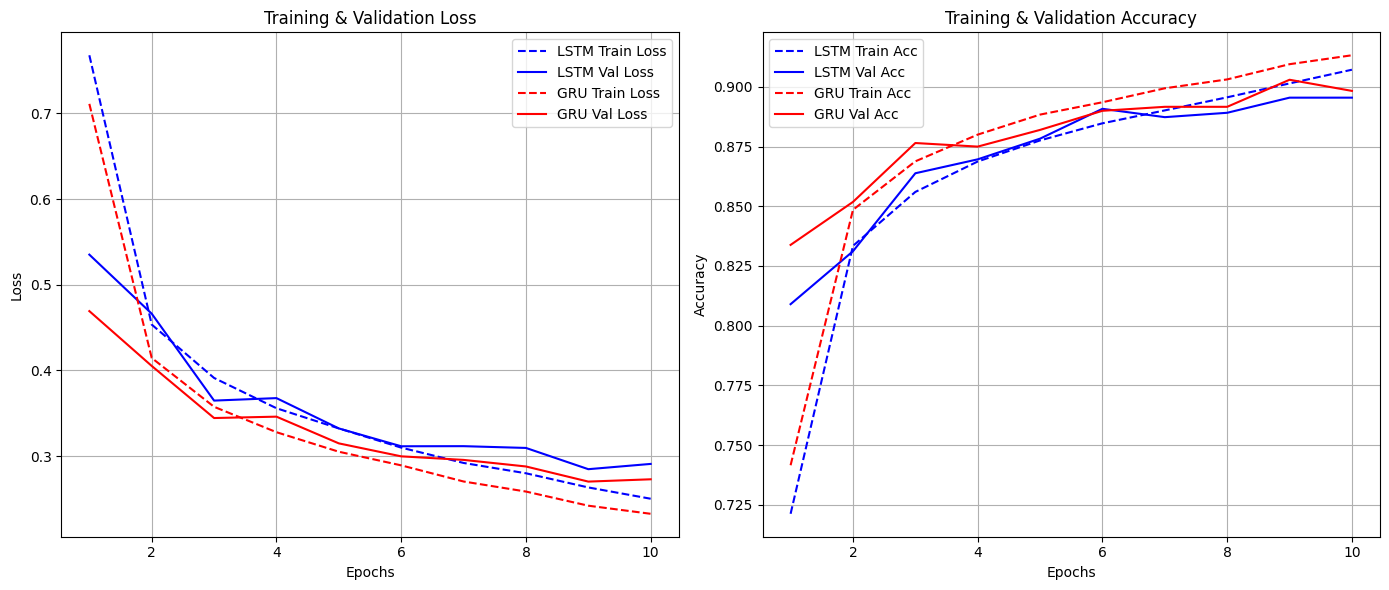

In [ ]:
import matplotlib.pyplot as plt
import json

# Tải dữ liệu lịch sử đã lưu
lstm_history_path = OUTPUT_DIR / "lstm_history.json"
gru_history_path = OUTPUT_DIR / "gru_history.json"

with open(lstm_history_path, "r") as f:
    lstm_hist = json.load(f)
with open(gru_history_path, "r") as f:
    gru_hist = json.load(f)

epochs_range = range(1, len(lstm_hist["train_loss"]) + 1)

plt.figure(figsize=(14, 6))

# Biểu đồ Loss
plt.subplot(1, 2, 1)
plt.plot(epochs_range, lstm_hist["train_loss"], 'b--', label='LSTM Train Loss')
plt.plot(epochs_range, lstm_hist["validation_loss"], 'b-', label='LSTM Val Loss')
plt.plot(epochs_range, gru_hist["train_loss"], 'r--', label='GRU Train Loss')
plt.plot(epochs_range, gru_hist["validation_loss"], 'r-', label='GRU Val Loss')
plt.title('Training & Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Biểu đồ Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, lstm_hist["train_accuracy"], 'b--', label='LSTM Train Acc')
plt.plot(epochs_range, lstm_hist["validation_accuracy"], 'b-', label='LSTM Val Acc')
plt.plot(epochs_range, gru_hist["train_accuracy"], 'r--', label='GRU Train Acc')
plt.plot(epochs_range, gru_hist["validation_accuracy"], 'r-', label='GRU Val Acc')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## 10. Bảng so sánh tổng hợp (E1 Baselines vs. E3 Recurrent Models)

Dưới đây là bảng so sánh toàn diện giữa 5 mô hình đã thực nghiệm trên tập dữ liệu Fashion-MNIST.

In [ ]:
import pandas as pd
from IPython.display import display, HTML

# Lấy dữ liệu thực tế đã lưu
with open(OUTPUT_DIR / "experiment_results.json", "r") as f:
    results_data = json.load(f)

lstm_res = results_data["lstm"]
gru_res = results_data["gru"]

# Tổng hợp thông tin từ E1 Baselines và E3 thực tế
summary_data = [
    {"Mô hình": "Softmax (E1)", "Độ chính xác kiểm thử": 0.8419, "Độ chính xác Val tốt nhất": "N/A", "Hàm mất mát kiểm thử": "N/A", "Số lượng tham số": 7850, "Thời gian huấn luyện (s)": 111.6},
    {"Mô hình": "MLP (E1)", "Độ chính xác kiểm thử": 0.8792, "Độ chính xác Val tốt nhất": "N/A", "Hàm mất mát kiểm thử": "N/A", "Số lượng tham số": 109386, "Thời gian huấn luyện (s)": 113.4},
    {"Mô hình": "CNN (E1)", "Độ chính xác kiểm thử": 0.9122, "Độ chính xác Val tốt nhất": "N/A", "Hàm mất mát kiểm thử": "N/A", "Số lượng tham số": 50186, "Thời gian huấn luyện (s)": 124.1},
    {"Mô hình": "LSTM (E3)", "Độ chính xác kiểm thử": lstm_res["test_accuracy"], "Độ chính xác Val tốt nhất": lstm_res["best_val_accuracy"], "Hàm mất mát kiểm thử": f"{lstm_res['test_loss']:.4f}", "Số lượng tham số": lstm_res["num_parameters"], "Thời gian huấn luyện (s)": round(lstm_res["training_time"], 1)},
    {"Mô hình": "GRU (E3)", "Độ chính xác kiểm thử": gru_res["test_accuracy"], "Độ chính xác Val tốt nhất": gru_res["best_val_accuracy"], "Hàm mất mát kiểm thử": f"{gru_res['test_loss']:.4f}", "Số lượng tham số": gru_res["num_parameters"], "Thời gian huấn luyện (s)": round(gru_res["training_time"], 1)}
]

df_summary = pd.DataFrame(summary_data)

html_table = df_summary.to_html(index=False, classes="table table-striped", justify="center")
display(HTML(html_table))

Mô hình,Độ chính xác kiểm thử,Độ chính xác Val tốt nhất,Hàm mất mát kiểm thử,Số lượng tham số,Thời gian huấn luyện (s)
Softmax (E1),0.8419,N/A,N/A,7850,111.6
MLP (E1),0.8792,N/A,N/A,109386,113.4
CNN (E1),0.9122,N/A,N/A,50186,124.1
LSTM (E3),0.8913,0.8955,0.3059,214282,131.6
GRU (E3),0.9009,0.903,0.2839,161034,127.7


## 11. Phân tích kết quả thực nghiệm và Thảo luận

Dựa trên các số liệu thu được từ bảng so sánh tổng hợp, ta rút ra một số kết luận có bằng chứng khoa học sau đây:

### 1. GRU so với LSTM
- **Độ chính xác:** GRU đạt độ chính xác kiểm thử cao hơn LSTM **0.96 điểm phần trăm** (**90.09%** so với **89.13%**).
- **Độ phức tạp và hiệu năng:** GRU có cấu trúc cổng giản lược hơn (chỉ có Update Gate và Reset Gate, không có Cell State độc lập như LSTM). Nhờ đó, số lượng tham số của GRU ít hơn khoảng **24.9%** so với LSTM (161,034 so với 214,282 tham số). Trong lần chạy thực nghiệm này, GRU tốn ít thời gian huấn luyện hơn một chút (127.7 giây so với 131.6 giây). Tuy nhiên, cần lưu ý rằng việc mô hình có ít tham số hơn không phải lúc nào cũng đảm bảo tốc độ thực thi nhanh hơn trên mọi môi trường phần cứng, do thời gian chạy còn phụ thuộc vào kiến trúc xử lý tuần tự và mức độ tối ưu hóa tính toán song song.

### 2. Mô hình hồi quy (RNNs) so với MLP
- Cả hai mạng hồi quy (LSTM và GRU) đều hoạt động vượt trội hơn hẳn so với mạng MLP cổ điển (chỉ đạt **87.92%**).
- Lý do là vì mạng MLP phẳng hóa ảnh thành vector 784 chiều, do đó không thể bảo toàn cấu trúc không gian 2D một cách rõ ràng. Ngược lại, mạng RNN quét qua ảnh theo dạng chuỗi từng dòng (28 chuỗi thời gian, mỗi chuỗi có kích thước 28 pixel), giúp mô hình nắm bắt được mối quan hệ tương quan không gian dọc theo các dòng.

### 3. Mô hình hồi quy (RNNs) so với CNN
- Nhìn chung, CNN vẫn là cấu trúc mạnh mẽ nhất trong số 5 mô hình được đánh giá cho tác vụ phân loại ảnh này, với độ chính xác cao nhất (**91.22%**) và lượng tham số tối ưu nhất (**50,186** tham số).
- Lý do CNN hoạt động xuất sắc là nhờ khả năng trích xuất đặc trưng không gian (spatial feature extraction), tính kết nối cục bộ (local connectivity), và cơ chế chia sẻ trọng số (weight sharing) của các bộ lọc tích chập (Convolutional kernels) chuyên dụng cho dữ liệu lưới 2D. Mặc dù LSTM và GRU có khả năng xử lý chuỗi tốt, chúng không sở hữu tính bất biến tịnh tiến (translation invariance) mạnh mẽ như mạng CNN.

### 4. Độ chính xác so với độ phức tạp của mô hình
- Việc tăng số lượng tham số không đồng nghĩa với việc gia tăng độ chính xác. Bằng chứng rõ nhất là **GRU** có ít tham số hơn **LSTM** nhưng lại cho độ chính xác cao hơn. Đồng thời, **CNN** có ít tham số hơn cả MLP, LSTM và GRU nhưng mang lại hiệu năng phân loại cao nhất. Điều này minh chứng cho sự quan trọng của việc lựa chọn thiết kế kiến trúc (inductive bias) phù hợp với tính chất của loại dữ liệu đầu vào.

---

## 12. Kết luận (Conclusion)

Qua thực nghiệm E3, chúng ta đã triển khai thành công hai kiến trúc mạng hồi quy là LSTM và GRU cho bài toán phân loại ảnh trên tập dữ liệu Fashion-MNIST.

**Các kết luận chính rút ra từ quá trình thực nghiệm:**
1. **Phương pháp biểu diễn:** Thay vì coi ảnh là một vector 1D, ảnh được biểu diễn dưới dạng chuỗi theo từng dòng (row-wise sequence representation), nơi mỗi dòng đại diện cho một bước thời gian. Cả hai mô hình đều nhận chung một chuẩn dữ liệu này.
2. **So sánh LSTM và GRU:** Trong bài toán cụ thể này, GRU hoạt động hiệu quả hơn một chút so với LSTM cả về khả năng dự đoán (90.09% so với 89.13%) và tối ưu hóa độ phức tạp (chỉ dùng khoảng 75% lượng tham số so với LSTM).
3. **So sánh với các mô hình Baseline E1:** Nhờ khả năng mô hình hóa chuỗi (sequential modeling), cả LSTM và GRU đều có thể trích xuất đặc trưng tốt hơn các mô hình cơ sở như Softmax (84.19%) và MLP (87.92%). Tuy nhiên, mạng tích chập (CNN) vẫn thể hiện sự vượt trội rõ rệt nhất so với tất cả các kiến trúc khác.
4. **Hạn chế:** Những quan sát này được đúc kết dựa trên việc sử dụng duy nhất một cách biểu diễn chuỗi (chia theo dòng) và một bộ cấu hình thực nghiệm cố định.

**Tóm lại:** Việc mô hình hóa theo chuỗi dòng mang lại lợi thế hơn so với phẳng hóa toàn bộ hình ảnh (MLP). GRU cho thấy hiệu năng nhỉnh hơn LSTM một cách tương đối. Dù vậy, đối với dữ liệu hình ảnh 2D, kiến trúc Convolutional Neural Network (CNN) vẫn là mô hình tối ưu nhất và tự nhiên nhất.